# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Load the hotel data
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv"
df = pd.read_csv(url)

# Show the first 5 rows
display(df.head())

# Show summary statistics
display(df.describe())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,7069.000000,1011.000000,9404.000000,9404.000000,9404.000000,9404.000000
mean,0.248299,79.326244,2015.156104,37.026584,15.515313,1.155040,3.078690,1.864738,0.095279,0.015419,0.077839,0.419715,0.290196,0.238622,200.990946,219.550940,1.019034,86.843614,0.144938,0.613143
std,0.432049,87.584146,0.443661,11.083421,9.025545,1.124304,2.379227,1.198565,0.393858,0.125781,0.267933,2.726546,1.352679,0.630041,80.330753,104.296474,10.137928,53.759940,0.353264,0.835930
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,9.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,8.000000,2015.000000,31.000000,7.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,156.000000,135.000000,0.000000,45.000000,0.000000,0.000000
50%,0.000000,48.000000,2015.000000,38.000000,16.000000,1.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,223.000000,0.000000,71.550000,0.000000,0.000000
75%,0.000000,118.000000,2015.000000,45.000000,23.000000,2.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,241.000000,286.000000,0.000000,120.600000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,13.000000,33.000000,55.000000,10.000000,2.000000,1.000000,26.000000,26.000000,17.000000,468.000000,511.000000,122.000000,508.000000,2.000000,5.000000


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. There’s a lot of detail about each booking, like price and number of guests. I’d check for missing values and any prices or guest counts that look unusual.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [2]:
# Select features and remove duplicate bookings
features = [
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adr',
    'total_of_special_requests'
]

X = df.drop_duplicates()[features].copy()

# Make sure values are numeric and remove missing values
X = X.apply(pd.to_numeric, errors='coerce')
X = X.dropna()

# Remove negative values
X = X[(X >= 0).all(axis=1)]

# Remove unusually high or low booking times and prices
for column in ['lead_time', 'adr']:
    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)
    IQR = Q3 - Q1

    X = X[
        (X[column] >= Q1 - 1.5 * IQR) &
        (X[column] <= Q3 + 1.5 * IQR)
    ]

# Standardize the features
scaler = StandardScaler()
scaled_df = pd.DataFrame(
    scaler.fit_transform(X),
    columns=features,
    index=X.index
)

display(scaled_df.head())

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
2,-0.804502,-1.017725,-0.863124,-0.297449,-0.816352
3,-0.696944,-1.017725,-0.863124,-0.297449,-0.816352
4,-0.679018,-1.017725,-0.445541,0.128836,0.351431
6,-0.929985,-1.017725,-0.445541,0.295643,-0.816352
7,-0.768649,-1.017725,-0.445541,0.221506,0.351431


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I chose booking lead time, weekend nights, weekday nights, nightly price, and special requests since these show when guests book, how long they stay, their preferences, and etc.

2. I expect to find groups like last-minute guests, or guests who book longer or more expensive stays.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

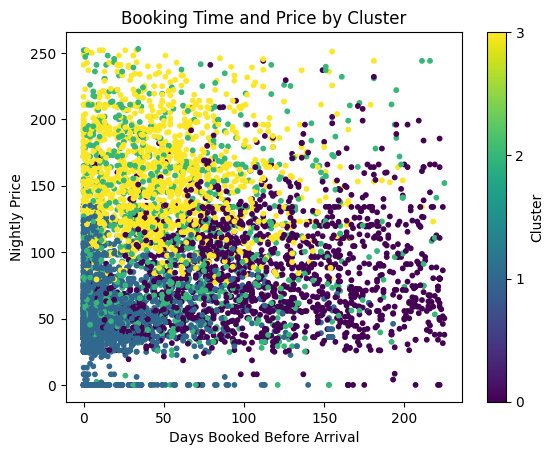

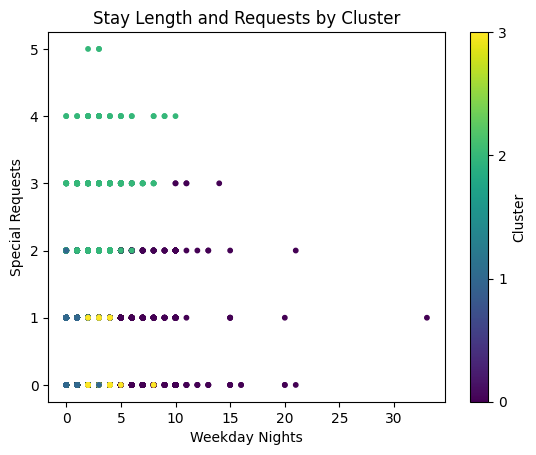

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
cluster,,,,,
0,110.40,2.37,5.81,83.95,0.54
1,16.27,0.45,1.43,52.46,0.36
2,59.23,1.12,3.06,116.03,2.26
3,49.93,1.13,3.15,152.32,0.42


In [3]:
# Create 4 clusters using the standardized features
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
X['cluster'] = kmeans.fit_predict(scaled_df[features])

# Plot 1: booking lead time and nightly price
plt.scatter(X['lead_time'], X['adr'], c=X['cluster'], cmap='viridis', s=10)
plt.xlabel('Days Booked Before Arrival')
plt.ylabel('Nightly Price')
plt.title('Booking Time and Price by Cluster')
plt.colorbar(label='Cluster', ticks=[0, 1, 2, 3])
plt.show()

# Plot 2: weekday nights and special requests
plt.scatter(
    X['stays_in_week_nights'],
    X['total_of_special_requests'],
    c=X['cluster'],
    cmap='viridis',
    s=10
)
plt.xlabel('Weekday Nights')
plt.ylabel('Special Requests')
plt.title('Stay Length and Requests by Cluster')
plt.colorbar(label='Cluster', ticks=[0, 1, 2, 3])
plt.show()

# Show the average feature values for each cluster
summary = X.groupby('cluster')[features].mean().round(2)
display(summary)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I chose k = 4 as a starting point because it gives the hotel a few customer groups to compare and target with different promotions.

2. Cluster 0 books far in advance and stays the longest, averaging about 8 nights. Cluster 1 books closer to arrival, stays about 2 nights, and pays the lowest nightly price. Cluster 2 stands out for making the most special requests. Cluster 3 pays the highest nightly price, averaging about $152.

## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

,Cluster 0,Cluster 1,Cluster 2,Cluster 3
2,0.495308,0.004104,0.492517,0.008071
3,0.000013,0.009533,0.973191,0.017263
4,0.000002,0.010254,0.780753,0.208991
6,0.531403,0.002372,0.455706,0.010519
7,0.023731,0.008309,0.761953,0.206007


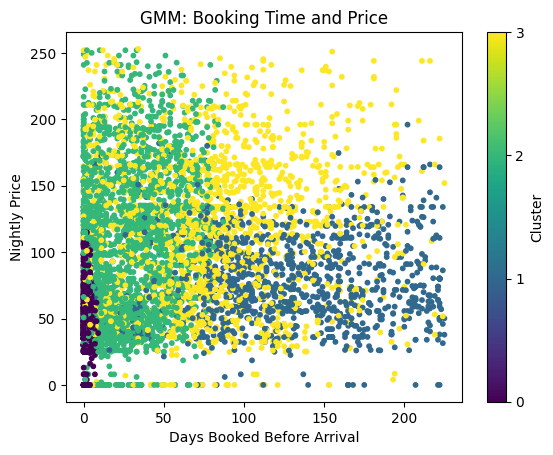

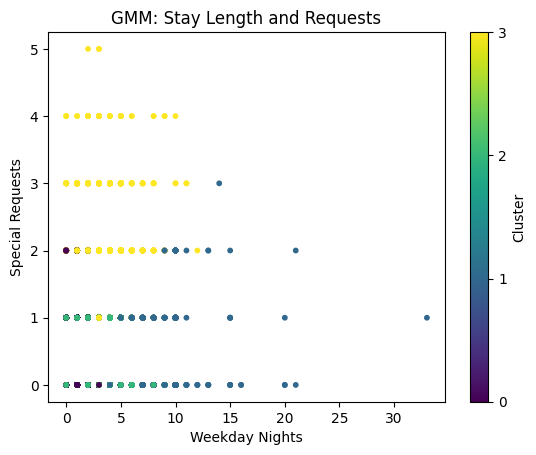

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
gmm_cluster,,,,,
0,1.73,0.24,1.02,47.43,0.40
1,127.99,2.23,5.66,76.25,0.37
2,28.25,1.09,2.82,101.72,0.32
3,78.34,1.27,3.44,119.58,1.69


In [4]:
# Fit GMM using the standardized features
gmm = GaussianMixture(n_components=4, random_state=42)
gmm.fit(scaled_df[features])

# Get the probability of belonging to each cluster
probabilities = gmm.predict_proba(scaled_df[features])

# Show the probabilities for the first 5 bookings
probability_table = pd.DataFrame(
    probabilities,
    columns=['Cluster 0', 'Cluster 1', 'Cluster 2', 'Cluster 3'],
    index=X.index
)
display(probability_table.head())

# Use the most likely cluster for the graphs and summary
X['gmm_cluster'] = probabilities.argmax(axis=1)

# Plot 1: booking lead time and nightly price
plt.scatter(X['lead_time'], X['adr'], c=X['gmm_cluster'], cmap='viridis', s=10)
plt.xlabel('Days Booked Before Arrival')
plt.ylabel('Nightly Price')
plt.title('GMM: Booking Time and Price')
plt.colorbar(label='Cluster', ticks=[0, 1, 2, 3])
plt.show()

# Plot 2: weekday nights and special requests
plt.scatter(
    X['stays_in_week_nights'],
    X['total_of_special_requests'],
    c=X['gmm_cluster'],
    cmap='viridis',
    s=10
)
plt.xlabel('Weekday Nights')
plt.ylabel('Special Requests')
plt.title('GMM: Stay Length and Requests')
plt.colorbar(label='Cluster', ticks=[0, 1, 2, 3])
plt.show()

# Show averages for each cluster
gmm_summary = X.groupby('gmm_cluster')[features].mean().round(2)
display(gmm_summary)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. Both models found guests with long stays + shorter, cheaper stays. GMM grouped guests who paid more and made more requests together, while KMeans put them in separate groups.

2. GMM could help the hotel decide which promotions to send guests who fit more than one group, and it could also show which guests have clear preferences and such.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [5]:
# Use the same standardized features for both models
data = scaled_df[features]

# Calculate the three metrics
def evaluate_model(labels):
    centers = data.groupby(labels).transform('mean')
    wcss = ((data - centers) ** 2).sum().sum()

    silhouette = silhouette_score(
        data, labels,
        sample_size=min(10000, len(data)),
        random_state=42
    )

    db_score = davies_bouldin_score(data, labels)

    return [wcss, silhouette, db_score]

# Compare the results
results = pd.DataFrame(
    [
        evaluate_model(X['cluster']),
        evaluate_model(X['gmm_cluster'])
    ],
    index=['KMeans', 'GMM'],
    columns=['WCSS', 'Silhouette Score', 'Davies-Bouldin Index']
)

display(results.round(3))

,WCSS,Silhouette Score,Davies-Bouldin Index
KMeans,18444.430,0.27,1.373
GMM,22223.188,0.12,1.748


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. KMeans performed better on all three metrics as it had lower WCSS, a higher Silhouette Score, and a lower Davies-Bouldin Index.

5.3. I would recommend KMeans for a business analyst because it is simple to explain and creates clear customer groups for marketing campaigns.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [6]:
# Show average values for each cluster
summary = X.groupby('cluster')[features].mean()

# Sort by booking lead time
display(summary.sort_values('lead_time').round(2))

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
cluster,,,,,
1,16.27,0.45,1.43,52.46,0.36
3,49.93,1.13,3.15,152.32,0.42
2,59.23,1.12,3.06,116.03,2.26
0,110.40,2.37,5.81,83.95,0.54


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. Cluster 0 books early and remains for a longer period of time. Cluster 1 has shorter and less expensive stays. Cluster 2 makes more special requests. Cluster 3 pays the highest nightly rates.

2. The hotel could provide Cluster 0 with early-booking offers, give Cluster 1 last-minute discounts, offer personalized service to Cluster 2, and give Cluster 3 room upgrades.

## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The most difficult aspect was working out the meaning of each group since there were no correct labels to refer to.

2. For the data which does not already have labels I would apply clustering in order to identify groups or patterns.

3. By clustering hotels are able to understand the various types of guests and thus provide them with more relevant offers and services.

4. This is linked to my learning outcome since I use Python to identify patterns in data and provide business recommendations.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [7]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] Converting notebook assignment_09_clustering.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 945754 bytes to assignment_09_clustering.html
